# 实验 11　基于计算语言学思路分析《三国演义》全文一致性

受《红楼梦》前 80 回与后 40 回作者争议的启发，本实验用可量化的语言特征检验《三国演义》前 80 回与后 40 回是否存在显著风格断裂。通常认为《三国演义》由罗贯中一人所著，但也存在“后人增补”“版本变迁”等说法。

## 特征工程

以每一回为一个样本，提取：

- 词汇丰富度 TTR（Type-Token Ratio）；
- 平均句长；
- 常用文言虚词频率（之、乎、者、也、矣、焉……）；
- 标点符号使用频率（逗号、句号等）；
- 词性分布（名词、动词、形容词比例，使用 `jieba.posseg`）。

## 三种验证方法

1. **可视化**：用 PCA 降维，观察两组样本是否自然分开。
2. **分类**：训练逻辑回归，看能否仅凭语言特征判断某回属于前半还是后半。
3. **统计检验**：对单个特征做 Mann-Whitney U 检验，看前后两组是否存在显著差异。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: sanguo-nlp-lab


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

from sanguo_nlp.coherency import style_features
from sanguo_nlp.corpus import load_chapters
from sanguo_nlp.plotting import use_chinese_font

use_chinese_font()

chapters = load_chapters()
features = style_features(chapters)
features.to_csv(TABLES_DIR / "style_features.csv", index=False, encoding="utf-8-sig")
print("特征表形状:", features.shape)
features.head()

Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/nx/fv3sdh3x51xb4259mz3dpkwc0000gp/T/jieba.cache


Loading model cost 0.435 seconds.


Prefix dict has been built successfully.


特征表形状: (120, 26)


,章号,TTR,平均句长,虚词_之,虚词_乎,虚词_者,虚词_也,虚词_矣,虚词_焉,虚词_而,...,虚词_与,标点_，,标点_。,标点_！,标点_？,标点_；,标点_：,名词占比,动词占比,形容词占比
0,1,0.431947,20.091324,0.949504,0.043159,0.194217,0.237376,0.043159,0.194217,0.258956,...,0.302115,8.912387,4.380665,0.172637,0.151057,0.474752,0.949504,0.283554,0.187146,0.016068
1,2,0.391272,19.003484,1.112850,0.034777,0.156495,0.330377,0.139106,0.034777,0.208659,...,0.452095,7.929056,4.190576,0.417319,0.347766,0.434707,1.408451,0.275144,0.207173,0.015551
2,3,0.382252,17.539326,1.411006,0.120943,0.282201,0.382987,0.201572,0.020157,0.322516,...,0.322516,6.853457,4.011288,0.604717,0.745817,0.443459,2.056037,0.247272,0.191844,0.017519
3,4,0.399595,17.962963,1.192795,0.000000,0.170399,0.316456,0.267770,0.024343,0.608569,...,0.365141,7.570594,3.943525,0.608569,0.681597,0.462512,2.239533,0.251772,0.221735,0.021600
4,5,0.395893,17.318033,0.643202,0.053600,0.125067,0.214401,0.071467,0.017867,0.268001,...,0.160800,7.646954,4.681079,0.410934,0.321601,0.428801,1.447204,0.297635,0.200936,0.015337


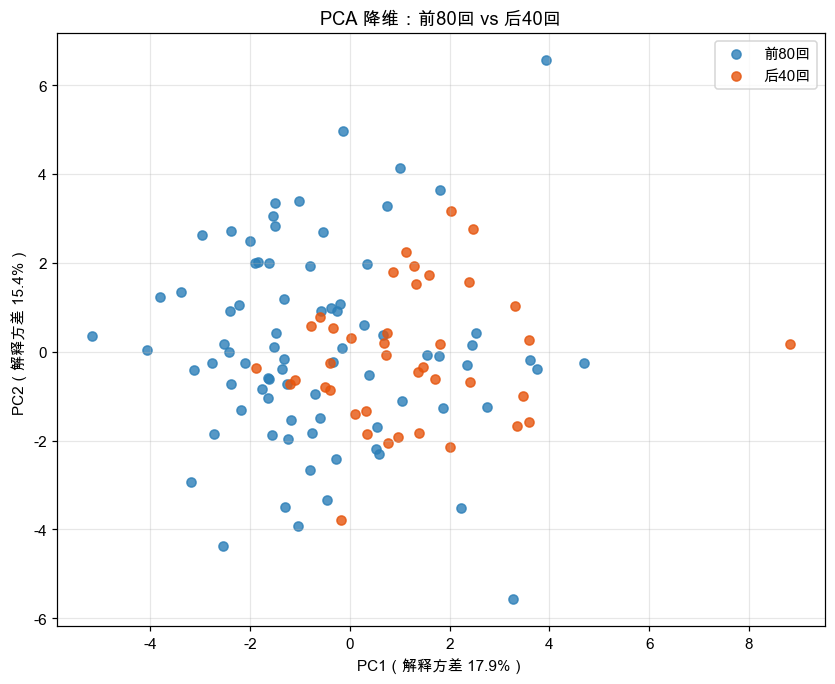

In [3]:
feature_columns = [column for column in features.columns if column != "章号"]
X = StandardScaler().fit_transform(features[feature_columns])
group = np.where(features["章号"] <= 80, "前80回", "后40回")

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 7))
for label, color in [("前80回", "#2c7fb8"), ("后40回", "#e6550d")]:
    mask = group == label
    ax.scatter(coords[mask, 0], coords[mask, 1], label=label, color=color, alpha=0.8)
ax.set_xlabel(f"PC1（解释方差 {pca.explained_variance_ratio_[0]:.1%}）")
ax.set_ylabel(f"PC2（解释方差 {pca.explained_variance_ratio_[1]:.1%}）")
ax.set_title("PCA 降维：前80回 vs 后40回")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIGURES_DIR / "pca_style_comparison.png")
plt.show()

In [4]:
model = LogisticRegression(max_iter=2000)
scores = cross_val_score(model, X, group, cv=5, scoring="accuracy")
baseline = max(np.bincount(group == "前80回")) / len(group)

print("5 折交叉验证准确率: %.3f ± %.3f" % (scores.mean(), scores.std()))
print("各折:", np.round(scores, 3))
print("多数类基线: %.3f" % baseline)

5 折交叉验证准确率: 0.767 ± 0.136
各折: [0.833 0.875 0.583 0.917 0.625]
多数类基线: 0.667


In [5]:
rows = []
for column in feature_columns:
    before = features.loc[features["章号"] <= 80, column]
    after = features.loc[features["章号"] > 80, column]
    statistic, p_value = mannwhitneyu(before, after, alternative="two-sided")
    rows.append(
        {
            "特征": column,
            "前80回均值": round(before.mean(), 4),
            "后40回均值": round(after.mean(), 4),
            "U统计量": statistic,
            "p值": p_value,
        }
    )

test_df = pd.DataFrame(rows).sort_values("p值")
test_df.to_csv(TABLES_DIR / "style_tests.csv", index=False, encoding="utf-8-sig")
print("未经多重比较校正时 p < 0.05 的特征数:", int((test_df["p值"] < 0.05).sum()), "/", len(test_df))
print(test_df.head(10).to_string(index=False))

未经多重比较校正时 p < 0.05 的特征数: 13 / 25
   特征  前80回均值  后40回均值   U统计量           p值
 平均句长 18.1867 20.0288  406.0 3.047837e-11
 虚词_与  0.3484  0.2463 2483.0 8.974041e-07
 标点_。  4.2163  3.9170 2404.0 7.709287e-06
 标点_；  0.4349  0.5227 1018.0 1.206989e-03
 虚词_而  0.4002  0.4725 1056.0 2.480775e-03
 标点_：  1.8072  1.6021 2128.0 3.318273e-03
 标点_？  0.4963  0.3962 2113.0 4.329515e-03
 虚词_也  0.3692  0.4226 1120.0 7.598981e-03
 标点_，  7.2831  7.4996 1120.0 7.598981e-03
形容词占比  0.0169  0.0182 1223.0 3.608362e-02


## 结论与反思

- **PCA**：两组样本大面积重叠，只在 PC1 方向呈现轻微的分组趋势，没有清晰的分界线；单看降维图无法把前后两半截然分开。
- **分类器**：逻辑回归 5 折交叉验证准确率约 **0.77 ± 0.14**，高于多数类基线 **0.67**，说明后半部分在部分语言特征上确实存在**可测量的弱差异**，但这种差异不足以构成“风格断裂”。
- **统计检验**：未做多重比较校正时有 13/25 个特征 p < 0.05，其中最显著的是平均句长（p ≈ 3e-11）和虚词“与”的频率；应结合效应量与整体图景判断，不能只挑单个显著特征下结论。
- **综合判断**：在“显著断裂”与“完全一致”之间，本结果更接近**全书连续、存在轻微风格漂移**。语言风格分析只能提供“可区分 / 不可区分”的统计证据，不能直接证明作者身份。

**实验记录**

- 思路受《红楼梦》语言风格定量分析启发，研究方法参考了相关文献并与 AI 助手讨论，随后在本地实现并交叉验证。